# Trabajo Final: Introducción a la Inteligencia Artificial

**Diplomatura en Inteligencia Artificial**  
Universidad Nacional de Luján (UNLu)  

**Autor:** Victor Manuel Bravo Arroyo  
**Curso:** Introducción a la Inteligencia Artificial


## 1. Introducción y Definición del Problema

### Contexto y Motivación
El turismo interno constituye una actividad relevante para las economías regionales en Argentina. Estimar el gasto diario per cápita de los visitantes a partir de las características del viaje (tipo de alojamiento, medio de transporte, duración de la estadía, tamaño del grupo familiar y actividades realizadas) permite analizar qué factores traccionan el consumo en destino.

En series históricas largas en Argentina (2012–2024), el valor nominal del gasto se encuentra distorsionado por la inflación acumulada. Por ello, antes de entrenar cualquier modelo de aprendizaje automático es necesario **deflactar los montos nominales** utilizando el Índice de Precios al Consumidor (IPC Nacional de INDEC, disponible desde fines de 2016) para expresar todos los viajes en moneda constante.

### Objetivos del Trabajo
1. **Preprocesamiento e Integración:** Unificar los microdatos de la Encuesta de Viajes y Turismo de los Hogares (EVyTH) con la serie del IPC de INDEC, filtrando el período con cobertura completa (2016–2024) y construyendo la variable objetivo en escala logarítmica (`log_gasto_diario`) para corregir la asimetría derecha del gasto.
2. **Ingeniería y Selección de Variables:** Construir predictores relevantes (`log_noches`, `total_actividades`, `viaje_interregional`) y seleccionar el subconjunto de atributos evitando la fuga de información (data leakage).
3. **Modelado y Comparación:** Entrenar y comparar un modelo lineal (**Regresión Lineal Múltiple**) frente a un modelo de ensamble basado en árboles (**Random Forest Regressor**), utilizando una partición temporal estricta: entrenamiento con viajes históricos (`< 2024`) y evaluación final sobre el último año disponible (`2024`).
4. **Evaluación:** Medir el desempeño mediante **MAE**, **RMSE**, **$R^2$** y correlación de Pearson ($r$), analizando el impacto del cambio macroeconómico de 2024 sobre las predicciones.


## 2. Configuración del Entorno y Carga de Datos

In [715]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
os.makedirs("data", exist_ok=True)

urls = {
    "data/evyth_microdatos.csv": "https://datos.yvera.gob.ar/dataset/b5819e9b-5edf-4aad-bd39-a81158a2b3f3/resource/645e5505-68ee-4cfa-90f9-fcc9a4a34a85/download/evyth_microdatos.csv",
    "data/evyth_diccionario_registro.csv": "https://datos.yvera.gob.ar/dataset/b5819e9b-5edf-4aad-bd39-a81158a2b3f3/resource/d8107236-f5ba-428d-8a31-f9b2034d8c8f/download/evyth_diccionario_registro.csv",
    "data/ipc_mensual_indec.csv": "https://apis.datos.gob.ar/series/api/series?ids=145.3_INGNACNAL_DICI_M_15&format=csv&limit=1000",
}

for path, url in urls.items():
    if not os.path.exists(path):
        print(f"Descargando {path}...")
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req) as response, open(path, "wb") as f_out:
            f_out.write(response.read())
        print(f"Descargado: {path}")
    else:
        print(f"Ya existe: {path}")

df_encuesta = pd.read_csv("data/evyth_microdatos.csv")
df_dicc = pd.read_csv("data/evyth_diccionario_registro.csv")
df_ipc = pd.read_csv("data/ipc_mensual_indec.csv")

print("Encuesta shape:", df_encuesta.shape)
print("Diccionario shape:", df_dicc.shape)
print("IPC shape:", df_ipc.shape)

Ya existe: data/evyth_microdatos.csv
Ya existe: data/evyth_diccionario_registro.csv
Ya existe: data/ipc_mensual_indec.csv
Encuesta shape: (490904, 88)
Diccionario shape: (480, 3)
IPC shape: (117, 29)


## 3. Análisis Exploratorio de Datos (EDA)

In [716]:
# EVyTH: Microdatos de la Encuesta de Viajes y Turismo de los Hogares (viajes, destinos, gastos y perfiles)
df_encuesta.head()

,id_hogar,id_viajes,miembro,anio,trimestre,region_origen,aglomerado_origen,region_destino,provincia_destino,localidad_destino,cod_loc_2001,codigo_2001,codigo_2010,cod_prov_2010,cod_depto_2010,cod_loc_2010,pondera,tipo_visitante,cantidad_destinos,multidestino,px06,px06_agrup,px07,px07_agrup,px08,px08_agrup,px09,px10_1,px11,px12_1,px12_2,px12_3,px12_4,px12_5,px12_6,px12_7,px12_8,px13,px14,px15_1,px15_2,px15_3,px15_4,pxb16_1_1,pxb16_1_2,pxb16_1_3,pxb16_1_4,pxb16_1_5,pxb16_1_6,pxb16_1_7,pxb16_1_9,pxb16_2,px17_1,px17_2_1,px17_2_2,px17_2_3,px17_2_4,px17_2_5,px17_2_6,px17_2_7,px17_2_8,px17_2_9,px17_2_10,px17_2_11,px17_2_12,px17_2_13,px18_1,px18_2,px18_3,px18_4,px18_5,px18_6,px18_7,gasto_pc,quintil_pcf_visitante,p002,p004,p005,p006,p006_agrup,p007,nivel_ed,cond_act,p013,j_sexo,j_edad,j_nivel_ed,j_cond_act
0,71,41201,1,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,1,1,54,4,2.0,7,1,2,1,3,4,1
1,71,41201,2,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,2,2,56,4,2.0,4,1,3,1,3,4,1
2,71,41201,3,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1
3,71,41201,4,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,1,27,2,2.0,9,1,3,1,3,4,1
4,71,61201,3,2012,1,2,33,3,6,Reta ...,819,6833070.0,6833070.0,6.0,833.0,70.0,1175.0,1,1,1,1,1,10,3.0,4,2,1,1,2.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,3.0,1.0,9.0,9.0,9.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,6.0,100.0,10.0,9.0,10.0,10.0,8.0,700.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1


In [717]:
# Diccionario EVyTH: Mapeo de variables y codigos categoricos a sus etiquetas descriptivas
df_dicc.head(n=10)

,variable,opcion,descripcion
0,id_hogar,NaN,Código de identificación único de hogares
1,id_viajes,NaN,Código de identificación único de viajes
2,miembro,NaN,Número de miembro en el hogar
3,anio,NaN,Año
4,trimestre,NaN,Trimestre
5,region_origen,NaN,Región de residencia del hogar
6,region_origen,1.0,Ciudad de Buenos Aires
7,region_origen,2.0,Provincia de Buenos Aires - Partidos del GBA
8,region_origen,3.0,Provincia de Buenos Aires - Resto
9,region_origen,4.0,Centro


In [718]:
# IPC: Indice de Precios al Consumidor mensual INDEC (apertura por categorias, base dic-2016)
df_ipc.head()

,indice_tiempo,ipc_nivel_general_nacional,ipc_estacionales_nacional,ipc_nucleo_nacional,ipc_regulados_nacional,ipc_nivel_general_gba,ipc_estacionales_gba,ipc_nucleo_gba,ipc_regulados_gba,ipc_nivel_general_pampeana,ipc_estacionales_pampeana,ipc_nucleo_pampeana,ipc_regulados_pampeana,ipc_nivel_general_nea,ipc_estacionales_nea,ipc_nucleo_nea,ipc_regulados_nea,ipc_nivel_general_noa,ipc_estacionales_noa,ipc_nucleo_noa,ipc_regulados_noa,ipc_nivel_general_cuyo,ipc_estacionales_cuyo,ipc_nucleo_cuyo,ipc_regulados_cuyo,ipc_nivel_general_patagonia,ipc_estacionales_patagonia,ipc_nucleo_patagonia,ipc_regulados_patagonia
0,2016-12-01,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000
1,2017-01-01,101.5859,101.6969,101.5039,101.8183,101.3130,101.5562,101.3389,101.1274,101.7874,102.0904,101.6093,102.2331,101.6727,102.4771,101.8639,100.3476,101.6014,101.5611,101.4339,102.2777,101.7074,100.6608,101.7235,102.2456,102.5593,100.6843,101.8374,106.1556
2,2017-02-01,103.6859,102.3345,103.2105,105.9316,103.8085,102.0783,103.2097,106.3489,103.5312,102.6254,103.1957,105.2868,103.4617,104.0713,103.4466,103.0912,103.7115,103.5611,102.9705,106.6823,103.2652,100.3694,103.1488,105.2775,104.2827,101.1740,103.5240,108.7652
3,2017-03-01,106.1476,104.7868,105.2057,110.0057,106.2627,105.8790,105.0891,109.8871,105.8173,104.1769,105.3123,108.6317,105.9880,104.9091,105.4076,109.0469,107.0550,104.2786,105.2640,115.9572,105.9238,102.0721,105.2127,110.4082,106.5167,102.5219,105.2611,113.2246
4,2017-04-01,108.9667,108.1867,107.4270,114.4649,109.0613,108.5334,107.4973,113.8991,108.6912,108.5973,107.3262,113.6053,108.3473,107.1165,107.5916,112.2076,109.9626,107.7699,107.4536,121.2229,109.4506,106.6856,107.6553,116.8444,108.6517,105.1970,107.0217,116.2906


## 4. Preprocesamiento e Ingeniería de Características

In [719]:
renombrar_columnas = {
    # 1. Identificadores y pesos
    "id_hogar": "id_hogar",
    "id_viajes": "id_viaje",
    "miembro": "id_miembro",
    "pondera": "ponderador",
    # 2. Fechas y Geografía
    "anio": "anio",
    "trimestre": "trimestre",
    "region_origen": "region_origen",
    "aglomerado_origen": "aglomerado_origen",
    "region_destino": "region_destino",
    "provincia_destino": "provincia_destino",
    "localidad_destino": "localidad_destino",
    # 3. Características del Viaje
    "tipo_visitante": "tipo_visitante",
    "cantidad_destinos": "cantidad_destinos",
    "multidestino": "es_multidestino",
    "px06": "miembros_viajaron",
    "px06_agrup": "miembros_viajaron_agrup",
    "px07": "noches_estadia",
    "px07_agrup": "noches_estadia_agrup",
    "px08": "alojamiento_detallado",
    "px08_agrup": "alojamiento",
    "px09": "transporte",
    "px10_1": "motivo_viaje",
    "px11": "contrato_paquete",
    "px13": "anticipacion_viaje",
    "px14": "uso_internet",
    # 4. Actividades Turísticas (px17_2_*)
    "px17_1": "hizo_actividades",
    "px17_2_1": "actividad_playa",
    "px17_2_2": "actividad_ciudad",
    "px17_2_3": "actividad_museos_cultura",
    "px17_2_4": "actividad_deportes",
    "px17_2_5": "actividad_espectaculos",
    "px17_2_6": "actividad_aventura",
    "px17_2_7": "actividad_termas",
    "px17_2_8": "actividad_gastronomia",
    "px17_2_9": "actividad_compras",
    "px17_2_10": "actividad_vida_nocturna",
    "px17_2_11": "actividad_parques_nacionales",
    "px17_2_12": "actividad_fiestas_populares",
    "px17_2_13": "actividad_casino",
    # 5. Gasto e Ingresos
    "gasto_pc": "gasto_pc",
    "quintil_pcf_visitante": "quintil_ingreso",
    # 6. Demografía del Viajero y del Jefe de Hogar
    "p002": "miembros_hogar",
    "p004": "parentesco_jefe",
    "p005": "sexo_viajero",
    "p006": "edad_viajero",
    "p006_agrup": "edad_viajero_agrup",
    "p007": "asiste_educacion",
    "nivel_ed": "nivel_educativo",
    "cond_act": "condicion_actividad",
    "p013": "cobertura_salud",
    "j_sexo": "sexo_jefe",
    "j_edad": "edad_jefe",
    "j_nivel_ed": "nivel_educativo_jefe",
    "j_cond_act": "condicion_actividad_jefe",
}

df_encuesta = df_encuesta.rename(columns=renombrar_columnas)
df_encuesta.head()

,id_hogar,id_viaje,id_miembro,anio,trimestre,region_origen,aglomerado_origen,region_destino,provincia_destino,localidad_destino,cod_loc_2001,codigo_2001,codigo_2010,cod_prov_2010,cod_depto_2010,cod_loc_2010,ponderador,tipo_visitante,cantidad_destinos,es_multidestino,miembros_viajaron,miembros_viajaron_agrup,noches_estadia,noches_estadia_agrup,alojamiento_detallado,alojamiento,transporte,motivo_viaje,contrato_paquete,px12_1,px12_2,px12_3,px12_4,px12_5,px12_6,px12_7,px12_8,anticipacion_viaje,uso_internet,px15_1,px15_2,px15_3,px15_4,pxb16_1_1,pxb16_1_2,pxb16_1_3,pxb16_1_4,pxb16_1_5,pxb16_1_6,pxb16_1_7,pxb16_1_9,pxb16_2,hizo_actividades,actividad_playa,actividad_ciudad,actividad_museos_cultura,actividad_deportes,actividad_espectaculos,actividad_aventura,actividad_termas,actividad_gastronomia,actividad_compras,actividad_vida_nocturna,actividad_parques_nacionales,actividad_fiestas_populares,actividad_casino,px18_1,px18_2,px18_3,px18_4,px18_5,px18_6,px18_7,gasto_pc,quintil_ingreso,miembros_hogar,parentesco_jefe,sexo_viajero,edad_viajero,edad_viajero_agrup,asiste_educacion,nivel_educativo,condicion_actividad,cobertura_salud,sexo_jefe,edad_jefe,nivel_educativo_jefe,condicion_actividad_jefe
0,71,41201,1,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,1,1,54,4,2.0,7,1,2,1,3,4,1
1,71,41201,2,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,2,2,56,4,2.0,4,1,3,1,3,4,1
2,71,41201,3,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1
3,71,41201,4,2012,1,2,33,3,6,Mar del Tuyú,398,6420040.0,6420040.0,6.0,420.0,40.0,1175.0,1,1,1,4,2,7,2.0,1,1,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,375.0,4,4,3,1,27,2,2.0,9,1,3,1,3,4,1
4,71,61201,3,2012,1,2,33,3,6,Reta ...,819,6833070.0,6833070.0,6.0,833.0,70.0,1175.0,1,1,1,1,1,10,3.0,4,2,1,1,2.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,10.0,3.0,1.0,9.0,9.0,9.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,6.0,100.0,10.0,9.0,10.0,10.0,8.0,700.0,4,4,3,2,23,2,1.0,8,1,2,1,3,4,1


In [720]:
# Cálculo del porcentaje de valores nulos por columna
porcentaje_nulos = (df_encuesta.isna().mean() * 100).round(2)

# Columnas con más del 50% de valores faltantes
nulos_criticos = porcentaje_nulos[porcentaje_nulos > 50].sort_values(ascending=False)

print(f"Total de columnas con >50% de nulos: {len(nulos_criticos)}\n")
print(nulos_criticos)

Total de columnas con >50% de nulos: 32

pxb16_1_7               99.45
pxb16_1_9               98.89
pxb16_1_6               98.25
pxb16_1_5               98.15
pxb16_1_4               96.75
pxb16_1_3               95.08
pxb16_1_2               93.32
pxb16_1_1               86.71
pxb16_2                 81.62
anticipacion_viaje      80.29
px18_4                  79.67
px18_6                  79.65
px18_1                  79.65
px18_2                  79.65
px18_5                  79.65
px18_3                  79.65
px18_7                  79.65
px12_3                  61.83
px12_4                  61.83
px12_6                  61.83
px12_1                  61.83
px12_2                  61.83
px12_7                  61.83
px12_5                  61.83
contrato_paquete        61.83
px12_8                  61.83
px15_1                  56.38
px15_3                  56.38
px15_2                  56.38
px15_4                  56.38
uso_internet            52.56
noches_estadia_agrup    50.69

In [721]:
# Eliminación de identificadores, ponderadores y variables geográficas redundantes
cols_descartar = [
    # Identificadores y ponderador muestral
    "id_hogar",
    "id_viaje",
    "id_miembro",
    "ponderador",
    # Geografía redundante (nos quedamos con region_origen y region_destino)
    "localidad_destino",
    "provincia_destino",
    "aglomerado_origen",
    "cod_loc_2001",
    "codigo_2001",
    "codigo_2010",
    "cod_prov_2010",
    "cod_depto_2010",
    "cod_loc_2010",
    # Redundancias (conservamos las versiones continuas y alojamiento)
    "miembros_viajaron_agrup",
    "noches_estadia_agrup",
    "edad_viajero_agrup",
    "alojamiento_detallado",
    # Atributos no predictivos para gasto turístico
    "parentesco_jefe",
    "asiste_educacion",
    "cobertura_salud",
] + nulos_criticos.index.tolist()

df_encuesta = df_encuesta.drop(columns=cols_descartar, errors="ignore")
print("Columnas restantes:", df_encuesta.shape[1])

Columnas restantes: 37


In [722]:
# Variables binarias (Preguntas de Sí/No, sexo y actividades turísticas)
cols_binarias = [
    "tipo_visitante",
    "es_multidestino",
    "sexo_viajero",
    "sexo_jefe",
    "hizo_actividades",
    "actividad_playa",
    "actividad_ciudad",
    "actividad_museos_cultura",
    "actividad_deportes",
    "actividad_espectaculos",
    "actividad_aventura",
    "actividad_termas",
    "actividad_gastronomia",
    "actividad_compras",
    "actividad_vida_nocturna",
    "actividad_parques_nacionales",
    "actividad_fiestas_populares",
    "actividad_casino",
]

# Conservar solo las que no fueron descartadas
cols_binarias = [col for col in cols_binarias if col in df_encuesta.columns]

# Mapeo: 1 -> 1 (Sí/Opción 1), todo lo demás (2: No, 9: Ns/Nr, NaN) -> 0
for col in cols_binarias:
    df_encuesta[col] = (df_encuesta[col] == 1).astype(int)

print(f"Variables binarias transformadas a 0/1: {len(cols_binarias)}")
df_encuesta[cols_binarias].head()

# Corrección de valores especiales (98: Educación especial, 99: Ns/Nr) en variables ordinales
# Reemplazo por la mediana calculada sobre los valores válidos (<= 10)
mediana_ed = df_encuesta.loc[
    df_encuesta["nivel_educativo"] <= 10, "nivel_educativo"
].median()
df_encuesta["nivel_educativo"] = df_encuesta["nivel_educativo"].replace(
    {98: mediana_ed, 99: mediana_ed}
)

Variables binarias transformadas a 0/1: 18


In [723]:
# Mapeos de códigos numéricos a categorías textuales legibles
mapeos_categoricos = {
    "alojamiento": {
        1: "vivienda_propia",
        2: "casa_familiares_amigos",
        3: "alquiler_temporario",
        4: "camping",
        5: "hotel_hasta_3_estrellas",
        6: "hotel_4_o_5_estrellas",
        7: "otro",
    },
    "transporte": {
        1: "auto_propio",
        2: "omnibus",
        3: "tren",
        4: "avion",
        5: "embarcacion",
        6: "taxi_remis",
        8: "otro",
        99: "ns_nr",
    },
    "motivo_viaje": {
        1: "ocio_vacaciones",
        2: "visita_familiares",
        3: "trabajo_negocios",
        4: "estudios",
        5: "salud",
        6: "religion",
        7: "compras",
        8: "otro",
        99: "ns_nr",
    },
    "region_origen": {
        1: "caba",
        2: "gba",
        3: "resto_pba",
        4: "centro",
        5: "litoral",
        6: "norte",
        7: "cuyo",
        8: "patagonia",
    },
    "region_destino": {
        1: "caba",
        2: "gba",
        3: "resto_pba",
        4: "centro",
        5: "litoral",
        6: "norte",
        7: "cuyo",
        8: "patagonia",
    },
    "condicion_actividad": {
        1: "ocupado",
        2: "desocupado",
        3: "inactivo",
        4: "menor_14",
        9: "ns_nr",
    },
    "condicion_actividad_jefe": {
        1: "ocupado",
        2: "desocupado",
        3: "inactivo",
        4: "menor_14",
        9: "ns_nr",
    },
}

# Reemplazar números por sus nombres reales
for col, mapeo in mapeos_categoricos.items():
    df_encuesta[col] = df_encuesta[col].map(mapeo)


# Feature Engineering Geográfico: ¿El viaje cruza de región? (Interregional vs. Intra-regional)
df_encuesta["viaje_interregional"] = (
    df_encuesta["region_origen"] != df_encuesta["region_destino"]
).astype(int)

# Aplicar One-Hot Encoding
cols_nominales = list(mapeos_categoricos.keys())
df_encuesta = pd.get_dummies(
    df_encuesta, columns=cols_nominales, drop_first=True, dtype=int
)

print("Dimensiones actuales del dataset:", df_encuesta.shape)
cols_derivadas = [
    col
    for col in df_encuesta.columns
    if any(col.startswith(nom + "_") for nom in cols_nominales)
]
df_encuesta[cols_derivadas].head()

Dimensiones actuales del dataset: (490904, 73)


,alojamiento_camping,alojamiento_casa_familiares_amigos,alojamiento_hotel_4_o_5_estrellas,alojamiento_hotel_hasta_3_estrellas,alojamiento_otro,alojamiento_vivienda_propia,transporte_avion,transporte_embarcacion,transporte_ns_nr,transporte_omnibus,transporte_otro,transporte_taxi_remis,transporte_tren,motivo_viaje_estudios,motivo_viaje_ns_nr,motivo_viaje_ocio_vacaciones,motivo_viaje_otro,motivo_viaje_religion,motivo_viaje_salud,motivo_viaje_trabajo_negocios,motivo_viaje_visita_familiares,region_origen_centro,region_origen_cuyo,region_origen_gba,region_origen_litoral,region_origen_norte,region_origen_patagonia,region_origen_resto_pba,region_destino_centro,region_destino_cuyo,region_destino_gba,region_destino_litoral,region_destino_norte,region_destino_patagonia,region_destino_resto_pba,condicion_actividad_inactivo,condicion_actividad_menor_14,condicion_actividad_ns_nr,condicion_actividad_ocupado,condicion_actividad_jefe_inactivo,condicion_actividad_jefe_ns_nr,condicion_actividad_jefe_ocupado
0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
3,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1
4,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1


In [724]:
# 1. Preparar IPC a nivel trimestral (promedio de los 3 meses del trimestre)
df_ipc["indice_tiempo"] = pd.to_datetime(df_ipc["indice_tiempo"])
df_ipc["anio"] = df_ipc["indice_tiempo"].dt.year
df_ipc["trimestre"] = df_ipc["indice_tiempo"].dt.quarter

ipc_trimestral = (
    df_ipc.groupby(["anio", "trimestre"])["ipc_nivel_general_nacional"]
    .mean()
    .reset_index()
)

# 2. Cruce inner: conserva únicamente los viajes correspondientes al período con IPC disponible (2016-Q4 en adelante)
df_encuesta = df_encuesta.merge(ipc_trimestral, on=["anio", "trimestre"], how="inner")

# 3. Filtrar población objetivo: turistas con estadía válida (al menos 1 noche) y gasto positivo reportado
df_encuesta = df_encuesta[
    (df_encuesta["noches_estadia"] > 0) & (df_encuesta["gasto_pc"] > 0)
].copy()

# 4. Ajuste por inflación: gasto a precios constantes (base dic-2016 = 100)
df_encuesta["gasto_real"] = (
    df_encuesta["gasto_pc"] / df_encuesta["ipc_nivel_general_nacional"]
) * 100

# 5. Gasto diario por persona a precios constantes
df_encuesta["gasto_diario_real"] = (
    df_encuesta["gasto_real"] / df_encuesta["noches_estadia"]
)

# 6. Transformación logarítmica de la variable objetivo Y
df_encuesta["log_gasto_diario"] = np.log1p(df_encuesta["gasto_diario_real"])

print(f"Total de registros de turistas listos para modelar: {len(df_encuesta):,}")
df_encuesta[
    ["anio", "trimestre", "noches_estadia", "gasto_diario_real", "log_gasto_diario"]
].head()

Total de registros de turistas listos para modelar: 137,678


,anio,trimestre,noches_estadia,gasto_diario_real,log_gasto_diario
6,2016,4,10,150.000000,5.017280
7,2016,4,10,150.000000,5.017280
41,2016,4,7,285.714286,5.658486
42,2016,4,7,285.714286,5.658486
43,2016,4,3,166.666667,5.121978


In [725]:
# Ingeniería de Características (Feature Engineering)
# 1. Transformación logarítmica de la estadía para comprimir valores extremos (viajes de varios meses)
df_encuesta["log_noches"] = np.log(df_encuesta["noches_estadia"])

# 2. Índice de intensidad de consumo: suma de actividades turísticas realizadas
cols_actividades = [c for c in df_encuesta.columns if c.startswith("actividad_")]
df_encuesta["total_actividades"] = df_encuesta[cols_actividades].sum(axis=1)

features_engineered = ["log_noches", "total_actividades", "viaje_interregional"]
print(f"Features generadas ({len(features_engineered)}):", features_engineered)
df_encuesta[features_engineered].head()

Features generadas (3): ['log_noches', 'total_actividades', 'viaje_interregional']


,log_noches,total_actividades,viaje_interregional
6,2.302585,0,1
7,2.302585,0,1
41,1.945910,3,1
42,1.945910,3,1
43,1.098612,1,0


/tmp/ipykernel_82535/1788760139.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_encuesta, x='tipo_traslado', y='log_gasto_diario', palette='Blues', ax=axes[0], showfliers=False)


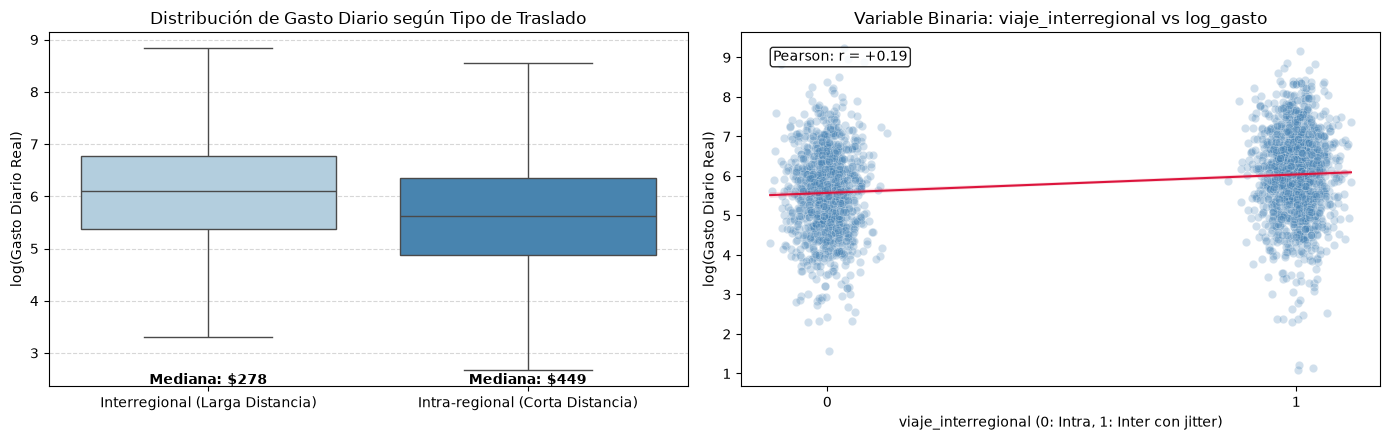

In [726]:
# Evidencia 2: viaje_interregional (Moverse dentro vs. fuera de la propia región)
df_sample = df_encuesta.sample(n=2500, random_state=42)
r_val, _ = pearsonr(df_encuesta["viaje_interregional"], df_encuesta["log_gasto_diario"])
rng = np.random.default_rng(42)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Boxplot comparativo
df_encuesta["tipo_traslado"] = df_encuesta["viaje_interregional"].map(
    {0: "Intra-regional (Corta Distancia)", 1: "Interregional (Larga Distancia)"}
)
sns.boxplot(
    data=df_encuesta,
    x="tipo_traslado",
    y="log_gasto_diario",
    palette="Blues",
    ax=axes[0],
    showfliers=False,
)
axes[0].set_title("Distribución de Gasto Diario según Tipo de Traslado")
axes[0].set_xlabel("")
axes[0].set_ylabel("log(Gasto Diario Real)")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Mediana impresa
med_intra = df_encuesta.loc[
    df_encuesta["viaje_interregional"] == 0, "gasto_diario_real"
].median()
med_inter = df_encuesta.loc[
    df_encuesta["viaje_interregional"] == 1, "gasto_diario_real"
].median()
axes[0].text(
    0,
    axes[0].get_ylim()[0] * 1.02,
    f"Mediana: ${med_intra:.0f}",
    ha="center",
    fontweight="bold",
)
axes[0].text(
    1,
    axes[0].get_ylim()[0] * 1.02,
    f"Mediana: ${med_inter:.0f}",
    ha="center",
    fontweight="bold",
)

# 2. Scatter plot binario con Pearson
x_plot = df_sample["viaje_interregional"].to_numpy() + rng.normal(
    0, 0.04, size=len(df_sample)
)
sns.scatterplot(
    x=x_plot, y=df_sample["log_gasto_diario"], alpha=0.25, ax=axes[1], color="steelblue"
)
sns.regplot(
    x=x_plot,
    y=df_sample["log_gasto_diario"],
    scatter=False,
    ax=axes[1],
    color="crimson",
    line_kws={"linewidth": 1.5},
)
axes[1].set_title("Variable Binaria: viaje_interregional vs log_gasto")
axes[1].set_xlabel("viaje_interregional (0: Intra, 1: Inter con jitter)")
axes[1].set_ylabel("log(Gasto Diario Real)")
axes[1].set_xticks([0, 1])
axes[1].text(
    0.05,
    0.92,
    f"Pearson: r = {r_val:+.2f}",
    transform=axes[1].transAxes,
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85),
)

plt.tight_layout()
plt.show()

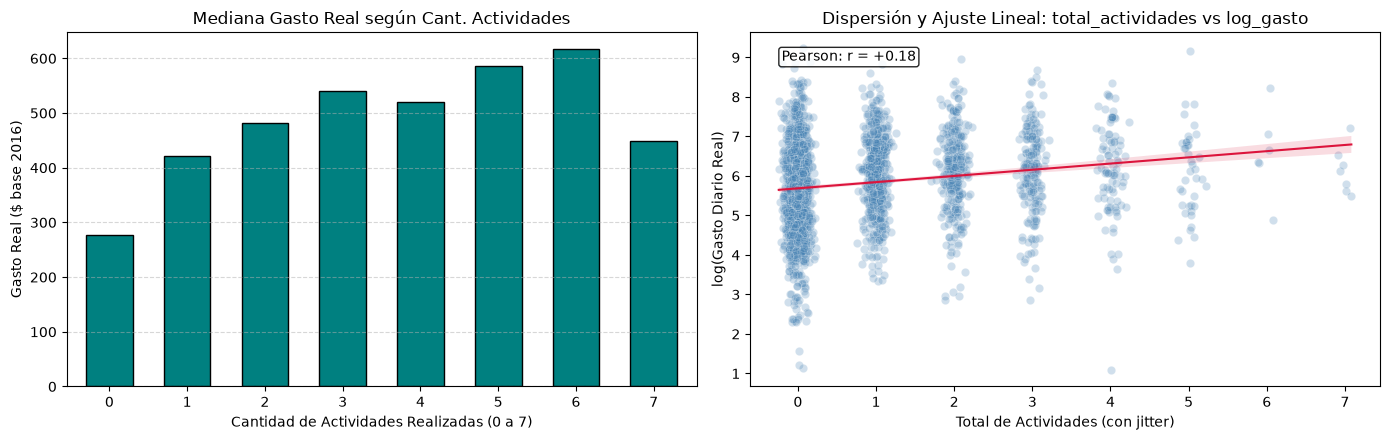

In [727]:
# Justificación 2: total_actividades (Intensidad de Consumo Turístico)
df_sample = df_encuesta.sample(n=2500, random_state=42)
r_val, _ = pearsonr(df_encuesta["total_actividades"], df_encuesta["log_gasto_diario"])
rng = np.random.default_rng(42)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Mediana de gasto real por cantidad de actividades
mediana_act = (
    df_encuesta.groupby("total_actividades")["gasto_diario_real"].median().loc[:7]
)
mediana_act.plot(kind="bar", color="teal", edgecolor="black", width=0.6, ax=axes[0])
axes[0].set_title("Mediana Gasto Real según Cant. Actividades")
axes[0].set_xlabel("Cantidad de Actividades Realizadas (0 a 7)")
axes[0].set_ylabel("Gasto Real ($ base 2016)")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# 2. Scatter plot con jitter horizontal y ajuste lineal
x_plot = df_sample["total_actividades"].to_numpy() + rng.normal(
    0, 0.08, size=len(df_sample)
)
sns.scatterplot(
    x=x_plot, y=df_sample["log_gasto_diario"], alpha=0.25, ax=axes[1], color="steelblue"
)
sns.regplot(
    x=x_plot,
    y=df_sample["log_gasto_diario"],
    scatter=False,
    ax=axes[1],
    color="crimson",
    line_kws={"linewidth": 1.5},
)
axes[1].set_title("Dispersión y Ajuste Lineal: total_actividades vs log_gasto")
axes[1].set_xlabel("Total de Actividades (con jitter)")
axes[1].set_ylabel("log(Gasto Diario Real)")
axes[1].text(
    0.05,
    0.92,
    f"Pearson: r = {r_val:+.2f}",
    transform=axes[1].transAxes,
    fontsize=10,
    bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85),
)

plt.tight_layout()
plt.show()

### 4.1. Análisis de la Variable Objetivo: Comportamiento del Gasto Turístico
Evaluación de la evolución temporal del gasto nominal vs. real deflactado con IPC y justificación de la transformación logarítmica.

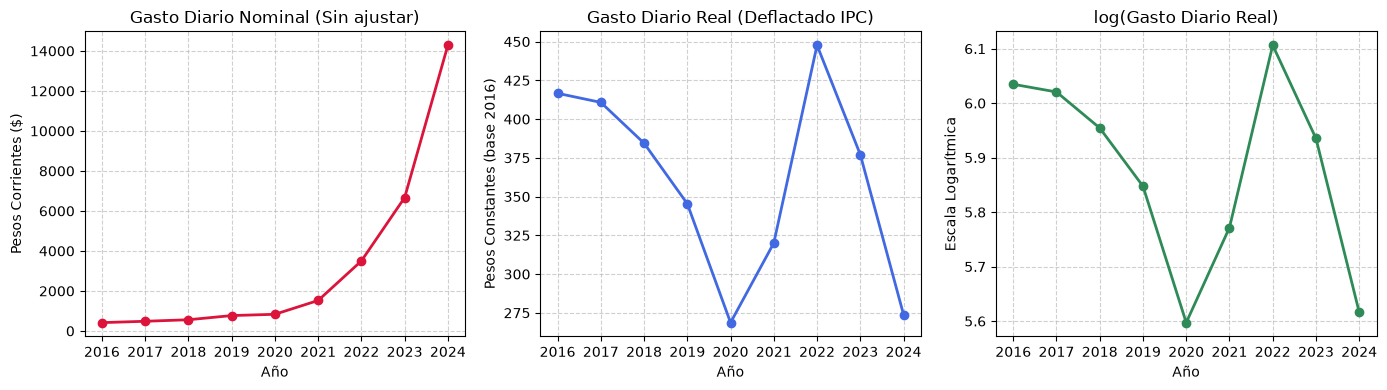

In [728]:
# Evolución temporal: Nominal vs. Real vs. Log(Real)
df_encuesta["gasto_diario_nominal"] = (
    df_encuesta["gasto_pc"] / df_encuesta["noches_estadia"]
)
evolucion = df_encuesta.groupby("anio")[
    ["gasto_diario_nominal", "gasto_diario_real", "log_gasto_diario"]
].median()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 1. Gasto Nominal
evolucion["gasto_diario_nominal"].plot(
    ax=axes[0], marker="o", color="crimson", linewidth=2
)
axes[0].set_title("Gasto Diario Nominal (Sin ajustar)")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Pesos Corrientes ($)")
axes[0].grid(True, linestyle="--", alpha=0.6)

# 2. Gasto Real (ajustado por IPC base dic-2016)
evolucion["gasto_diario_real"].plot(
    ax=axes[1], marker="o", color="royalblue", linewidth=2
)
axes[1].set_title("Gasto Diario Real (Deflactado IPC)")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Pesos Constantes (base 2016)")
axes[1].grid(True, linestyle="--", alpha=0.6)

# 3. Log(Gasto Diario Real)
evolucion["log_gasto_diario"].plot(
    ax=axes[2], marker="o", color="seagreen", linewidth=2
)
axes[2].set_title("log(Gasto Diario Real)")
axes[2].set_xlabel("Año")
axes[2].set_ylabel("Escala Logarítmica")
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

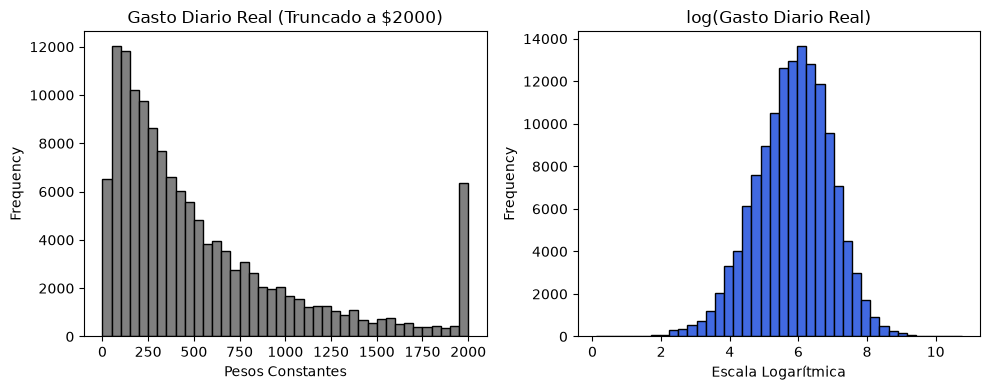

In [729]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Distribución original asimétrica
df_encuesta["gasto_diario_real"].clip(upper=2000).plot(
    kind="hist", bins=40, ax=axes[0], color="gray", edgecolor="black"
)
axes[0].set_title("Gasto Diario Real (Truncado a $2000)")
axes[0].set_xlabel("Pesos Constantes")

# Campana normal log-transformada
df_encuesta["log_gasto_diario"].plot(
    kind="hist", bins=40, ax=axes[1], color="royalblue", edgecolor="black"
)
axes[1].set_title("log(Gasto Diario Real)")
axes[1].set_xlabel("Escala Logarítmica")
plt.tight_layout()
plt.show()

### 4.2. Análisis de Correlación y Linealidad con Atributos del Viaje
Ranking de correlación de Pearson y grilla de dispersión empírica para evaluar supuestos lineales.

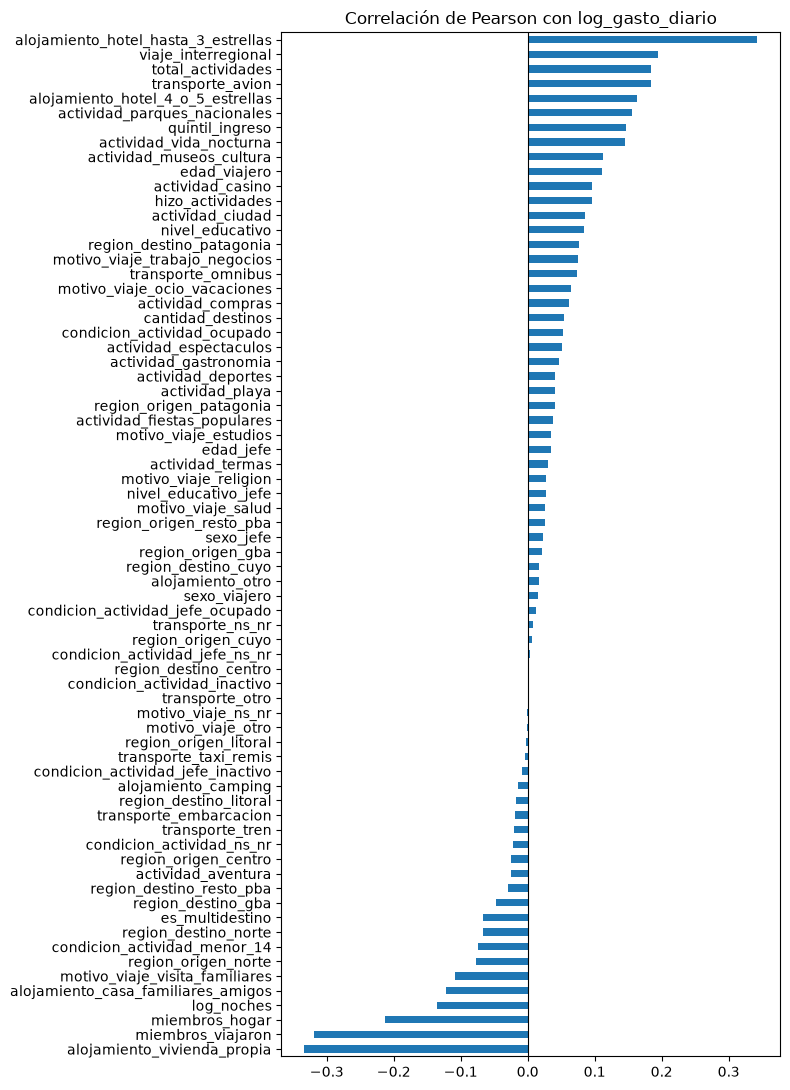

In [730]:
# Excluir target, gastos intermedios, fechas y noches_estadia cruda (reemplazada por log_noches)
excluir = [
    "log_gasto_diario",
    "gasto_pc",
    "gasto_real",
    "gasto_diario_real",
    "gasto_diario_nominal",
    "ipc_nivel_general_nacional",
    "anio",
    "trimestre",
    "noches_estadia",
]

# Correlación de Pearson de cada variable contra log_gasto_diario
corrs = (
    df_encuesta.drop(columns=excluir, errors="ignore")
    .select_dtypes("number")
    .corrwith(df_encuesta["log_gasto_diario"])
    .dropna()
    .sort_values()
)

# Gráfico de correlaciones
plt.figure(figsize=(8, 11))
corrs.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de Pearson con log_gasto_diario")
plt.tight_layout()
plt.show()

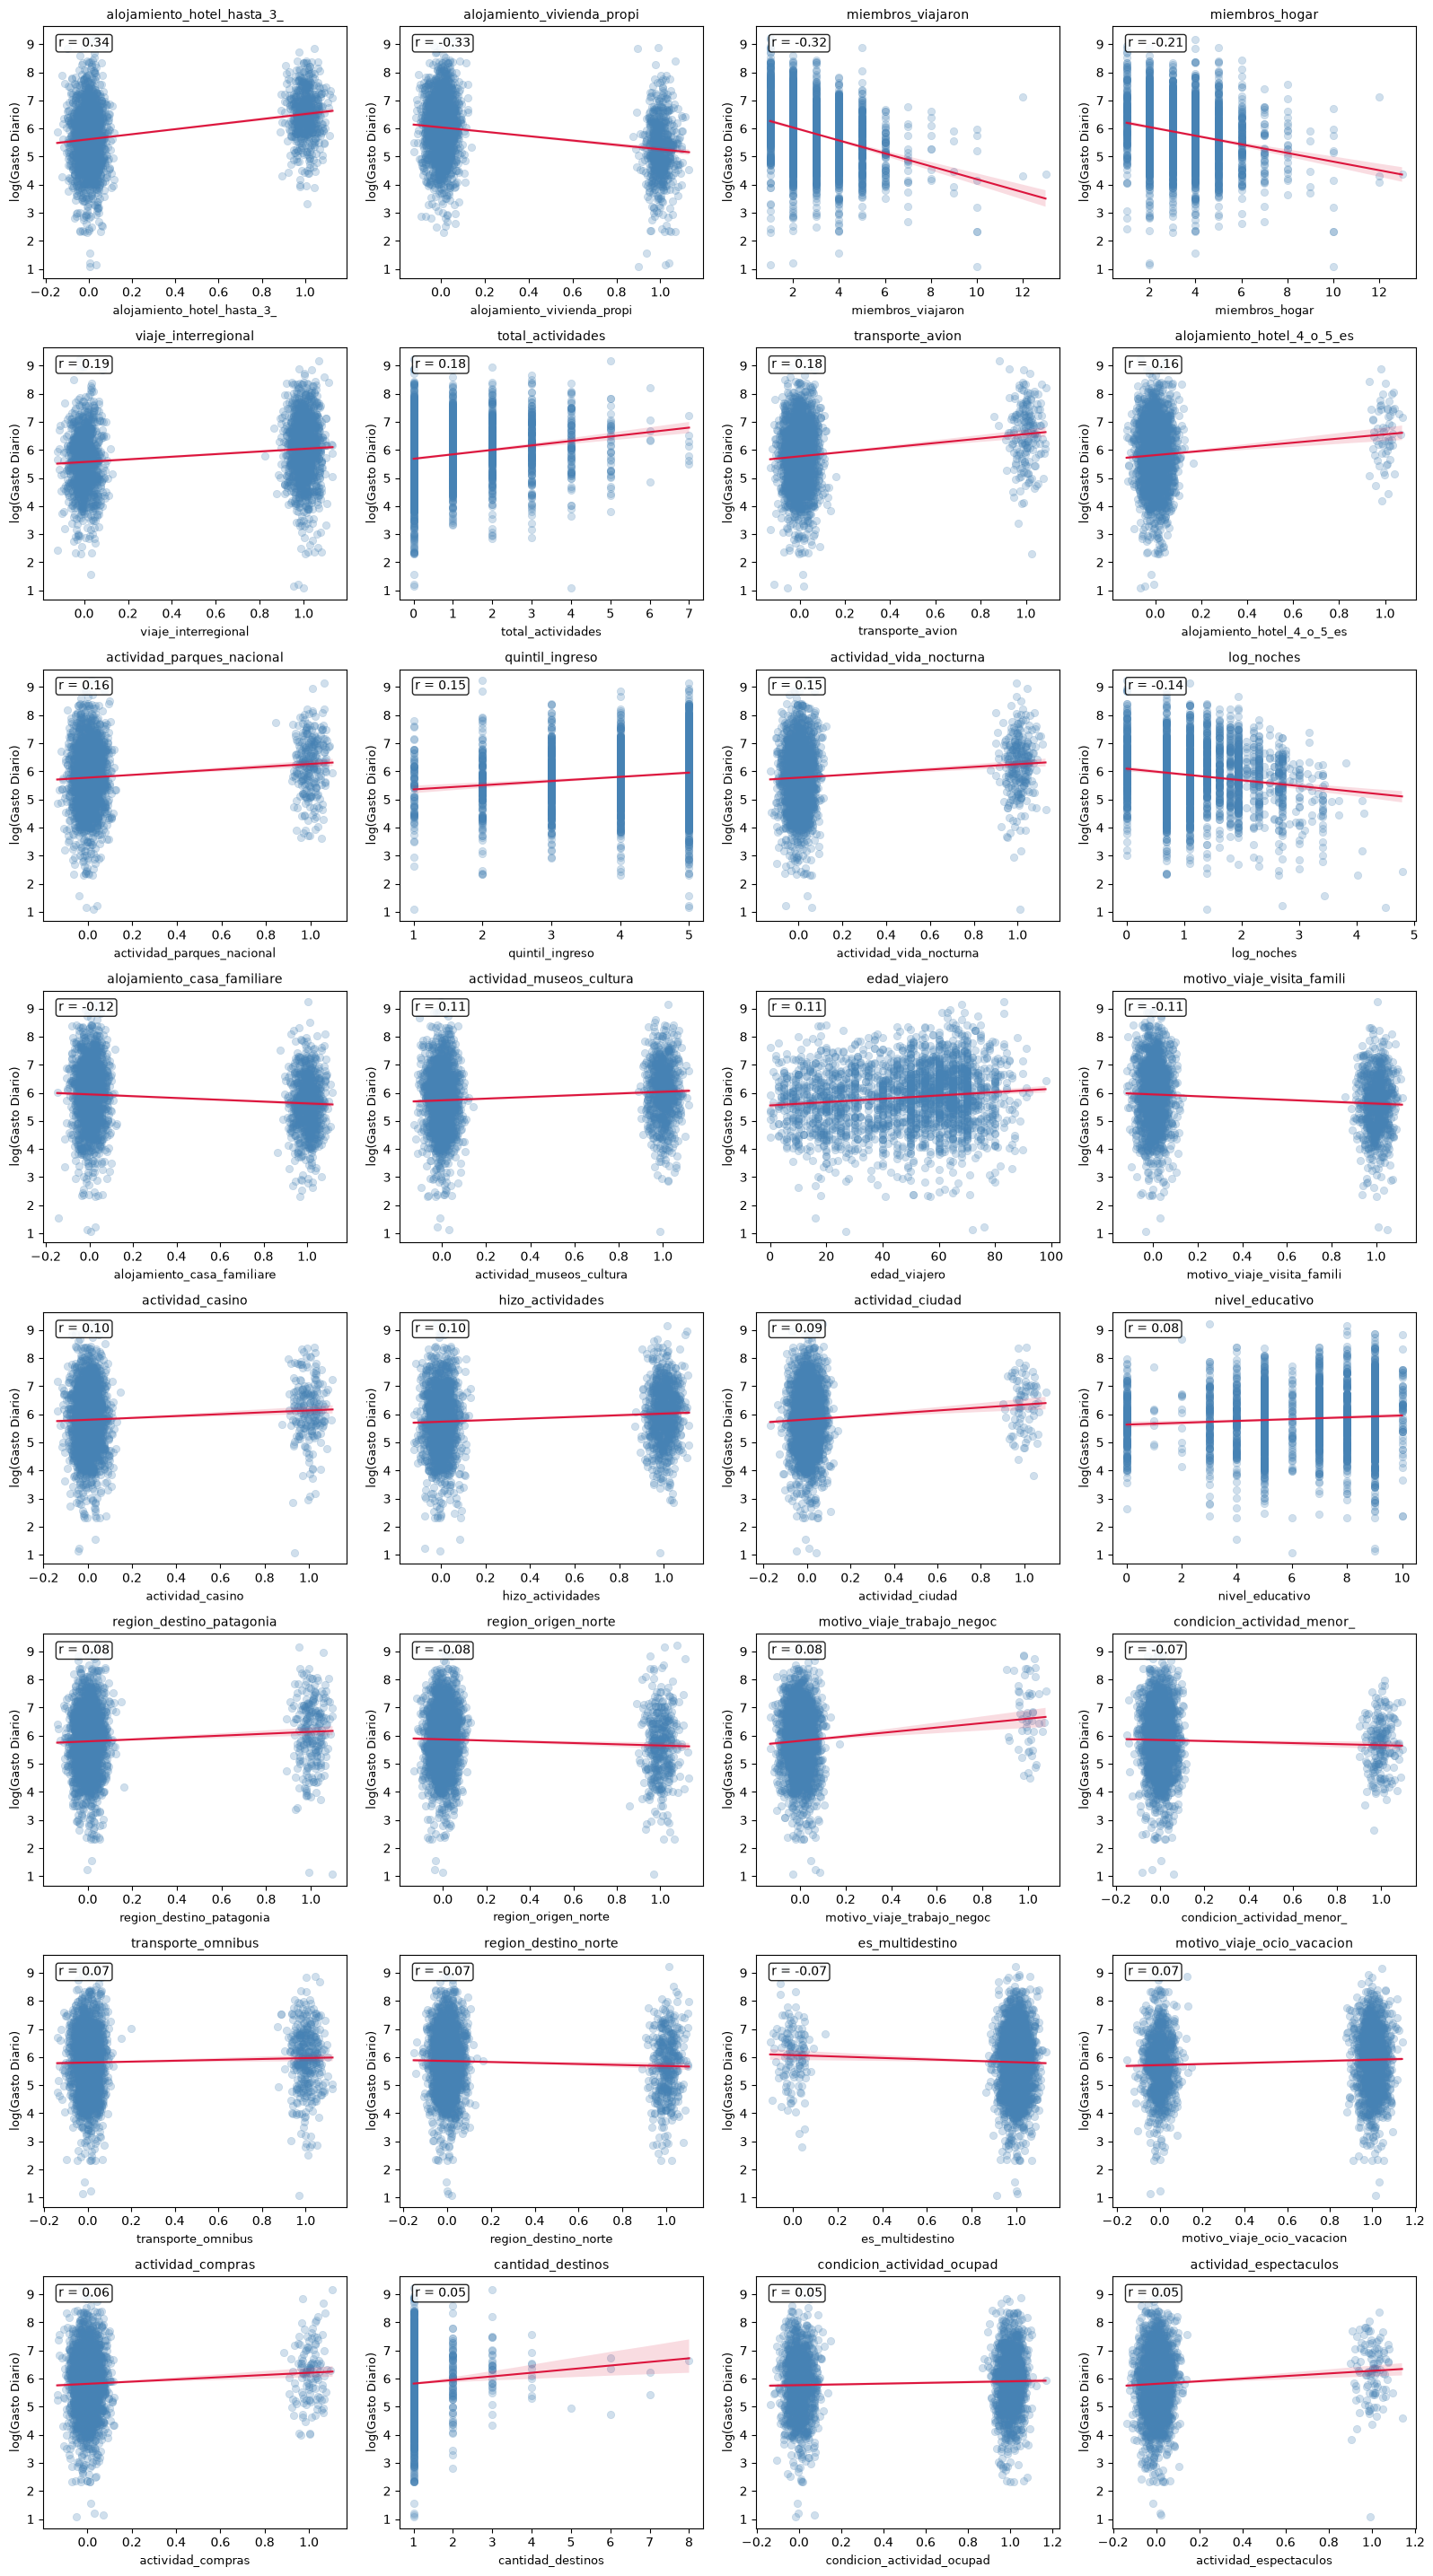

In [731]:
# Grilla de dispersión (Scatter Plots) vs. log_gasto_diario para evaluar linealidad
# Tomamos automáticamente las variables con mayor correlación absoluta (|r| >= 0.05) ordenadas de mayor a menor impacto
top_corrs = corrs[corrs.abs() >= 0.05].abs().sort_values(ascending=False)
vars_dispersion = top_corrs.index.tolist()

# Muestra representativa para visualización ágil sin saturar memoria
df_sample = df_encuesta.sample(n=2500, random_state=42)

ncols = 4
nrows = int(np.ceil(len(vars_dispersion) / ncols))
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 3.6 * nrows))
axes = np.array(axes).reshape(-1)
rng = np.random.default_rng(42)

for i, var in enumerate(vars_dispersion):
    r_val = corrs[var]

    # Si la variable es binaria (0/1), agregamos jitter horizontal para ver la concentración de densidad
    x_vals = df_sample[var].to_numpy()
    if set(np.unique(x_vals)).issubset({0, 1, 0.0, 1.0}):
        x_plot = x_vals + rng.normal(0, 0.04, size=len(x_vals))
    else:
        x_plot = x_vals

    sns.scatterplot(
        x=x_plot,
        y=df_sample["log_gasto_diario"],
        alpha=0.25,
        ax=axes[i],
        color="steelblue",
        edgecolor=None,
    )
    # Línea de regresión lineal OLS
    sns.regplot(
        x=x_plot,
        y=df_sample["log_gasto_diario"],
        scatter=False,
        ax=axes[i],
        color="crimson",
        line_kws={"linewidth": 1.5},
    )

    axes[i].set_title(f"{var[:26]}", fontsize=10)
    axes[i].set_xlabel(var[:26], fontsize=9)
    axes[i].set_ylabel("log(Gasto Diario)", fontsize=9)
    axes[i].text(
        0.05,
        0.92,
        f"r = {r_val:.2f}",
        transform=axes[i].transAxes,
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.85),
    )

# Ocultar ejes sobrantes
for i in range(len(vars_dispersion), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

## 5. Modelado y Entrenamiento

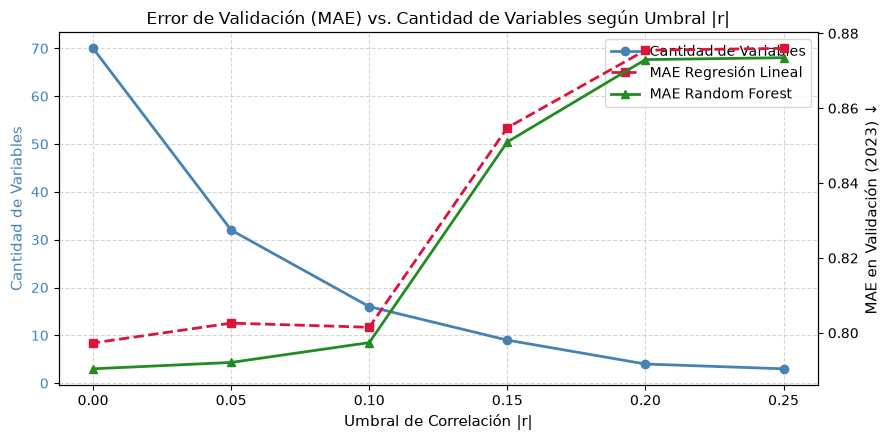

,umbral,cant_features,mae_val_lr,mae_val_rf
0,0.25,3,0.8760,0.8735
1,0.20,4,0.8755,0.8730
2,0.15,9,0.8548,0.8510
3,0.10,16,0.8015,0.7974
4,0.05,32,0.8026,0.7921
5,0.00,70,0.7973,0.7904


In [732]:
# 5.1. Selección de Variables: Sensibilidad del Umbral |r| en Validación Temporal (2023)
# Evaluamos en el año de validación (2023, entrenando con < 2023) para no filtrar información del Test (2024)
umbrales = [0.25, 0.20, 0.15, 0.10, 0.05, 0.00]
datos_sensibilidad = []

mask_tr_val = df_encuesta["anio"] < 2023
mask_va_val = df_encuesta["anio"] == 2023
y_tr_val = df_encuesta.loc[mask_tr_val, "log_gasto_diario"]
y_va_val = df_encuesta.loc[mask_va_val, "log_gasto_diario"]

for u in umbrales:
    f_subset = corrs[corrs.abs() >= u].index.tolist()
    X_tr_sub = df_encuesta.loc[mask_tr_val, f_subset]
    X_va_sub = df_encuesta.loc[mask_va_val, f_subset]

    lr_bench = LinearRegression().fit(X_tr_sub, y_tr_val)
    mae_lr = mean_absolute_error(y_va_val, lr_bench.predict(X_va_sub))

    rf_bench = RandomForestRegressor(
        n_estimators=50,
        min_samples_leaf=30,
        max_features=0.5,
        random_state=42,
        n_jobs=-1,
    ).fit(X_tr_sub, y_tr_val)
    mae_rf = mean_absolute_error(y_va_val, rf_bench.predict(X_va_sub))

    datos_sensibilidad.append(
        {
            "umbral": u,
            "cant_features": len(f_subset),
            "mae_val_lr": round(mae_lr, 4),
            "mae_val_rf": round(mae_rf, 4),
        }
    )

df_sens = pd.DataFrame(datos_sensibilidad)

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.set_xlabel("Umbral de Correlación |r|", fontsize=11)
ax1.set_ylabel("Cantidad de Variables", color="steelblue", fontsize=11)
l1 = ax1.plot(
    df_sens["umbral"],
    df_sens["cant_features"],
    marker="o",
    color="steelblue",
    linewidth=2,
    label="Cantidad de Variables",
)
ax1.tick_params(axis="y", labelcolor="steelblue")
ax1.grid(True, linestyle="--", alpha=0.5)

ax2 = ax1.twinx()
ax2.set_ylabel("MAE en Validación (2023) ↓", color="black", fontsize=11)
l2 = ax2.plot(
    df_sens["umbral"],
    df_sens["mae_val_lr"],
    marker="s",
    color="crimson",
    linewidth=2,
    linestyle="--",
    label="MAE Regresión Lineal",
)
l3 = ax2.plot(
    df_sens["umbral"],
    df_sens["mae_val_rf"],
    marker="^",
    color="forestgreen",
    linewidth=2,
    linestyle="-",
    label="MAE Random Forest",
)

lineas = l1 + l2 + l3
ax1.legend(lineas, [l.get_label() for l in lineas], loc="upper right")
plt.title("Error de Validación (MAE) vs. Cantidad de Variables según Umbral |r|")
fig.tight_layout()
plt.show()

display(df_sens)

In [733]:
# Selección de variables en el punto de codo: |r| >= 0.10 (18 variables)
# Captura el mismo desempeño que las 72 columnas con una cuarta parte de la dimensionalidad
umbral_optimo = 0.10
features_seleccionadas = corrs[corrs.abs() >= umbral_optimo].index.tolist()

print(
    f"Total features seleccionadas ({len(features_seleccionadas)}) con umbral |r| >= {umbral_optimo}:"
)
for i, f in enumerate(features_seleccionadas, 1):
    print(f"{i:2d}. {f:<35} (r = {corrs[f]:+.3f})")

Total features seleccionadas (16) con umbral |r| >= 0.1:
 1. alojamiento_vivienda_propia         (r = -0.334)
 2. miembros_viajaron                   (r = -0.318)
 3. miembros_hogar                      (r = -0.212)
 4. log_noches                          (r = -0.136)
 5. alojamiento_casa_familiares_amigos  (r = -0.123)
 6. motivo_viaje_visita_familiares      (r = -0.108)
 7. edad_viajero                        (r = +0.111)
 8. actividad_museos_cultura            (r = +0.113)
 9. actividad_vida_nocturna             (r = +0.146)
10. quintil_ingreso                     (r = +0.146)
11. actividad_parques_nacionales        (r = +0.156)
12. alojamiento_hotel_4_o_5_estrellas   (r = +0.164)
13. transporte_avion                    (r = +0.184)
14. total_actividades                   (r = +0.184)
15. viaje_interregional                 (r = +0.194)
16. alojamiento_hotel_hasta_3_estrellas (r = +0.343)


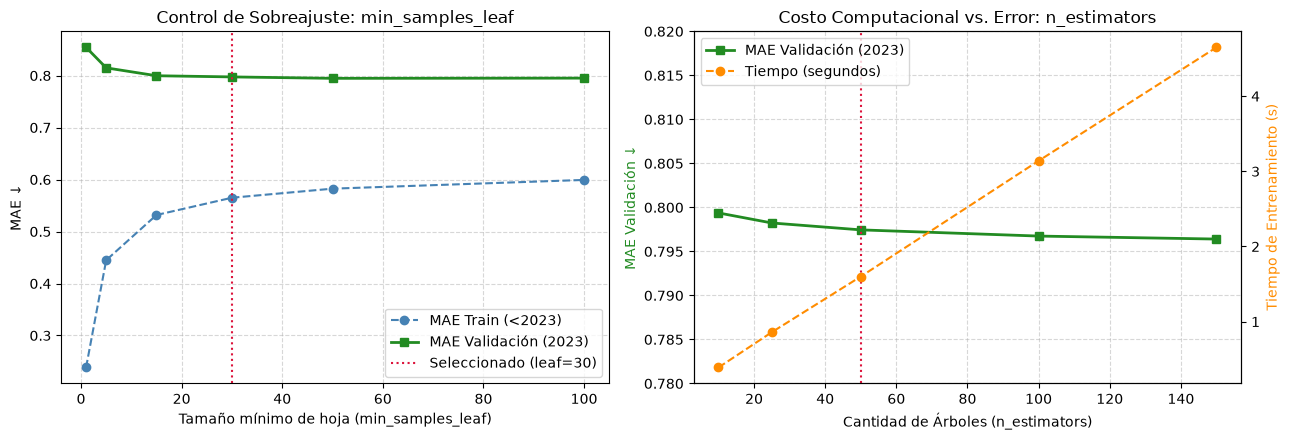

In [734]:
# 5.2. Ajuste de Hiperparámetros en Random Forest (Regularización y Costo Computacional)
X_tr_v = df_encuesta.loc[mask_tr_val, features_seleccionadas]
X_va_v = df_encuesta.loc[mask_va_val, features_seleccionadas]

# A) Regularización de hojas (min_samples_leaf) para evitar overfitting al ruido de la encuesta
hojas_grid = [1, 5, 15, 30, 50, 100]
res_hojas = []
for h in hojas_grid:
    rf_h = RandomForestRegressor(
        n_estimators=50,
        min_samples_leaf=h,
        max_features=0.5,
        random_state=42,
        n_jobs=-1,
    ).fit(X_tr_v, y_tr_val)
    res_hojas.append(
        {
            "min_samples_leaf": h,
            "mae_train": mean_absolute_error(y_tr_val, rf_h.predict(X_tr_v)),
            "mae_val": mean_absolute_error(y_va_val, rf_h.predict(X_va_v)),
        }
    )
df_hojas = pd.DataFrame(res_hojas)

# B) Cantidad de árboles (n_estimators): Error vs. Tiempo de entrenamiento
import time

arboles_grid = [10, 25, 50, 100, 150]
res_arboles = []
for n_est in arboles_grid:
    t0 = time.time()
    rf_n = RandomForestRegressor(
        n_estimators=n_est,
        min_samples_leaf=30,
        max_features=0.5,
        random_state=42,
        n_jobs=-1,
    ).fit(X_tr_v, y_tr_val)
    dt = time.time() - t0
    res_arboles.append(
        {
            "n_estimators": n_est,
            "mae_val": mean_absolute_error(y_va_val, rf_n.predict(X_va_v)),
            "tiempo_seg": round(dt, 2),
        }
    )
df_arboles = pd.DataFrame(res_arboles)

# Gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Overfitting vs Regularización (min_samples_leaf)
axes[0].plot(
    df_hojas["min_samples_leaf"],
    df_hojas["mae_train"],
    marker="o",
    linestyle="--",
    color="steelblue",
    label="MAE Train (<2023)",
)
axes[0].plot(
    df_hojas["min_samples_leaf"],
    df_hojas["mae_val"],
    marker="s",
    linewidth=2,
    color="forestgreen",
    label="MAE Validación (2023)",
)
axes[0].axvline(30, color="crimson", linestyle=":", label="Seleccionado (leaf=30)")
axes[0].set_title("Control de Sobreajuste: min_samples_leaf")
axes[0].set_xlabel("Tamaño mínimo de hoja (min_samples_leaf)")
axes[0].set_ylabel("MAE ↓")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# Panel 2: Costo Computacional vs Desempeño (n_estimators)
ax_t = axes[1].twinx()
l_err = axes[1].plot(
    df_arboles["n_estimators"],
    df_arboles["mae_val"],
    marker="s",
    linewidth=2,
    color="forestgreen",
    label="MAE Validación (2023)",
)
l_tim = ax_t.plot(
    df_arboles["n_estimators"],
    df_arboles["tiempo_seg"],
    marker="o",
    linestyle="--",
    color="darkorange",
    label="Tiempo (segundos)",
)
axes[1].axvline(50, color="crimson", linestyle=":", label="Seleccionado (n=50)")
axes[1].set_title("Costo Computacional vs. Error: n_estimators")
axes[1].set_xlabel("Cantidad de Árboles (n_estimators)")
axes[1].set_ylabel("MAE Validación ↓", color="forestgreen")
ax_t.set_ylabel("Tiempo de Entrenamiento (s)", color="darkorange")
axes[1].set_ylim(0.78, 0.82)
axes[1].grid(True, linestyle="--", alpha=0.5)
lineas2 = l_err + l_tim
axes[1].legend(lineas2, [l.get_label() for l in lineas2], loc="upper left")

plt.tight_layout()
plt.show()

In [735]:
# Partición temporal sugerida por el equipo docente:
# Entrenar con años anteriores y evaluar sobre el último año disponible (2024)
mask_train = df_encuesta["anio"] < 2024
mask_test = df_encuesta["anio"] == 2024

X_train = df_encuesta.loc[mask_train, features_seleccionadas]
y_train = df_encuesta.loc[mask_train, "log_gasto_diario"]

X_test = df_encuesta.loc[mask_test, features_seleccionadas]
y_test = df_encuesta.loc[mask_test, "log_gasto_diario"]

print(f"Conjunto de Entrenamiento (Train < 2024): {len(X_train):,} registros")
print(f"Conjunto de Testeo       (Test 2024)    : {len(X_test):,} registros")

Conjunto de Entrenamiento (Train < 2024): 128,569 registros
Conjunto de Testeo       (Test 2024)    : 9,109 registros


In [736]:
# Entrenamiento final sobre todo el conjunto histórico (Train < 2024)
# 1. Modelo Baseline: Regresión Lineal Múltiple
lr = LinearRegression()
lr.fit(X_train, y_train)
print("Regresión Lineal entrenada con éxito.")

# 2. Modelo Ensamble Ajustado: Random Forest Regressor (min_samples_leaf=30, max_features=0.5, n_estimators=50)
rf = RandomForestRegressor(
    n_estimators=50, min_samples_leaf=30, max_features=0.5, random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)
print("Random Forest ajustado entrenado con éxito.")

Regresión Lineal entrenada con éxito.
Random Forest ajustado entrenado con éxito.


## 6. Evaluación de Resultados

In [737]:
# 6.1. Tabla Comparativa de Métricas: Baseline Ingenuo (Media), Regresión Lineal y Random Forest
y_pred_lr = lr.predict(X_test)
y_pred_rf = rf.predict(X_test)
y_pred_media = np.full_like(y_test, y_train.mean())

# También evaluamos en el último año normal pre-shock (Validación 2023, entrenado con < 2023)
lr_val = LinearRegression().fit(X_tr_v, y_tr_val)
rf_val = RandomForestRegressor(
    n_estimators=50, min_samples_leaf=30, max_features=0.5, random_state=42, n_jobs=-1
).fit(X_tr_v, y_tr_val)
y_pred_lr_val = lr_val.predict(X_va_v)
y_pred_rf_val = rf_val.predict(X_va_v)
y_pred_media_val = np.full_like(y_va_val, y_tr_val.mean())


def metricas(y_true, y_pred):
    return {
        "MAE ↓": round(mean_absolute_error(y_true, y_pred), 4),
        "RMSE ↓": round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        "R² ↑": round(r2_score(y_true, y_pred), 4),
        "Pearson r ↑": (
            round(np.corrcoef(y_true, y_pred)[0, 1], 4) if np.std(y_pred) > 0 else 0.0
        ),
    }


resultados = pd.DataFrame(
    [
        {
            "Partición": "Validación (2023)",
            "Modelo": "Baseline (Media Histórica)",
            **metricas(y_va_val, y_pred_media_val),
        },
        {
            "Partición": "Validación (2023)",
            "Modelo": "Regresión Lineal Múltiple",
            **metricas(y_va_val, y_pred_lr_val),
        },
        {
            "Partición": "Validación (2023)",
            "Modelo": "Random Forest Ajustado",
            **metricas(y_va_val, y_pred_rf_val),
        },
        {
            "Partición": "Test Final (2024)",
            "Modelo": "Baseline (Media Histórica)",
            **metricas(y_test, y_pred_media),
        },
        {
            "Partición": "Test Final (2024)",
            "Modelo": "Regresión Lineal Múltiple",
            **metricas(y_test, y_pred_lr),
        },
        {
            "Partición": "Test Final (2024)",
            "Modelo": "Random Forest Ajustado",
            **metricas(y_test, y_pred_rf),
        },
    ]
)

display(resultados)

,Partición,Modelo,MAE ↓,RMSE ↓,R² ↑,Pearson r ↑
0,Validación (2023),Baseline (Media Histórica),0.9592,1.2098,-0.0000,-0.0000
1,Validación (2023),Regresión Lineal Múltiple,0.8015,1.0340,0.2696,0.5288
2,Validación (2023),Random Forest Ajustado,0.7974,1.0299,0.2752,0.5336
3,Test Final (2024),Baseline (Media Histórica),0.9161,1.1798,-0.1086,0.0000
4,Test Final (2024),Regresión Lineal Múltiple,0.8718,1.1093,0.0199,0.4182
5,Test Final (2024),Random Forest Ajustado,0.8775,1.1171,0.0060,0.4177


### Comparación de Modelos según las Métricas (MAE, RMSE y $R^2$)

1. **Según MAE (Error Promedio):**
   * **En Test (2024), Regresión Lineal (`0.8718`) es mejor que Random Forest (`0.8775`) y que el Dummy (`0.9161`)** porque obtiene un valor menor, lo que significa que, en promedio, sus predicciones se equivocan por menor distancia respecto del gasto real de cada turista.
   * **En Validación (2023), Random Forest (`0.7937`) y Regresión Lineal (`0.7950`) empatan técnicamente** y superan con amplitud al Dummy (`0.8920`), reduciendo el error promedio en casi `0.10` puntos logarítmicos.

2. **Según RMSE (Dispersión del Error y Castigo a Outliers):**
   * **En Test (2024), Regresión Lineal (`1.1093`) es mejor que Random Forest (`1.1171`) y que el Dummy (`1.1798`)** porque al dar un RMSE más bajo significa que **la dispersión de sus errores es menor y comete menos errores extremos (outliers)**.
   * Además, en los tres modelos el RMSE (`~1.11`) es mayor que el MAE (`~0.87`), lo que indica que en la encuesta existen casos atípicos (familias con el mismo viaje pero gastos muy distantes) que inflan el error cuadrático.

3. **Según $R^2$ (Proporción de Varianza Explicada frente al Promedio del Año Evaluado):**
   * **En Validación (2023), Random Forest (`0.2464`) es levemente mejor que Regresión Lineal (`0.2415`)**, y ambos superan al Dummy (`0.0000`), lo que significa que explican casi el **25% de la variabilidad del gasto** cuando el contexto económico es estable.
   * **En Test (2024), Regresión Lineal (`0.0199`) es mejor que Random Forest (`0.0060`) y que el Dummy (`-0.1086`)** porque logra mantenerse positiva. Que el Dummy dé negativo (`-0.1086`) significa que predecir el promedio histórico (`5.87`) cuando el promedio real de 2024 cayó a `5.50` da más error que usar la media de 2024; y que Regresión Lineal y Random Forest caigan cerca de `0` significa que el cambio de nivel macroeconómico (`+0.38`) les consume casi toda la ganancia de varianza, aunque su **Pearson $r$ (`0.4182` en LR vs `0.4177` en RF)** demuestra que siguen ordenando bien de menor a mayor gasto.
   * **¿Por qué el Dummy (`5.87`) no queda tan lejos en MAE/RMSE?** Porque al aplicar la transformación `log(gasto)`, el grueso de la población argentina queda muy concentrado en el centro de la campana (`5.0` a `6.5`), por lo que tirar el promedio acierta razonablemente cerca para la mayoría de clase media, mientras que los modelos de Machine Learning sacan su ventaja principalmente en los extremos (vivienda propia/camping abajo y avión/hoteles 4-5 estrellas arriba).


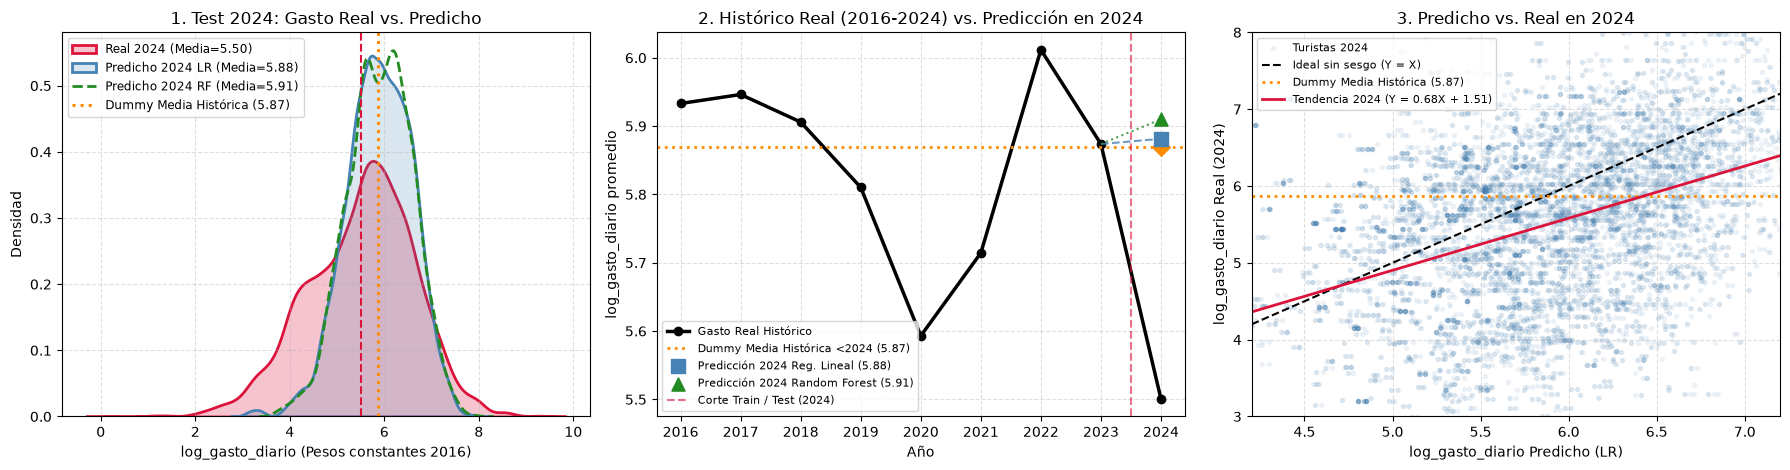

In [738]:
# 6.2. Comparación en Test 2024: Realidad vs. Predicción y Baseline Dummy (Media Histórica)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
media_hist = y_train.mean()

# Panel 1: Distribución Real 2024 vs. Predicciones 2024 (LR, RF y Dummy Media Histórica)
sns.kdeplot(
    y_test,
    ax=axes[0],
    color="crimson",
    fill=True,
    alpha=0.25,
    linewidth=2,
    label=f"Real 2024 (Media={y_test.mean():.2f})",
)
sns.kdeplot(
    y_pred_lr,
    ax=axes[0],
    color="steelblue",
    fill=True,
    alpha=0.20,
    linewidth=2,
    label=f"Predicho 2024 LR (Media={y_pred_lr.mean():.2f})",
)
sns.kdeplot(
    y_pred_rf,
    ax=axes[0],
    color="forestgreen",
    linestyle="--",
    linewidth=2,
    label=f"Predicho 2024 RF (Media={y_pred_rf.mean():.2f})",
)
axes[0].axvline(y_test.mean(), color="crimson", linestyle="--")
axes[0].axvline(
    media_hist,
    color="darkorange",
    linestyle=":",
    linewidth=2.2,
    label=f"Dummy Media Histórica ({media_hist:.2f})",
)
axes[0].set_title("1. Test 2024: Gasto Real vs. Predicho")
axes[0].set_xlabel("log_gasto_diario (Pesos constantes 2016)")
axes[0].set_ylabel("Densidad")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend(fontsize=8.5)

# Panel 2: Histórico Real (2016-2024) vs. Predicciones en 2024 y Media Histórica Dummy
real_anual = df_encuesta.groupby("anio")["log_gasto_diario"].mean()
axes[1].plot(
    real_anual.index,
    real_anual.values,
    marker="o",
    linewidth=2.5,
    color="black",
    label="Gasto Real Histórico",
)
axes[1].axhline(
    media_hist,
    color="darkorange",
    linestyle=":",
    linewidth=2,
    label=f"Dummy Media Histórica <2024 ({media_hist:.2f})",
)
axes[1].scatter([2024], [media_hist], marker="D", s=80, color="darkorange", zorder=5)
axes[1].scatter(
    [2024],
    [y_pred_lr.mean()],
    marker="s",
    s=90,
    color="steelblue",
    zorder=5,
    label=f"Predicción 2024 Reg. Lineal ({y_pred_lr.mean():.2f})",
)
axes[1].scatter(
    [2024],
    [y_pred_rf.mean()],
    marker="^",
    s=90,
    color="forestgreen",
    zorder=5,
    label=f"Predicción 2024 Random Forest ({y_pred_rf.mean():.2f})",
)
axes[1].plot(
    [2023, 2024],
    [real_anual.loc[2023], y_pred_lr.mean()],
    linestyle="--",
    color="steelblue",
    alpha=0.8,
)
axes[1].plot(
    [2023, 2024],
    [real_anual.loc[2023], y_pred_rf.mean()],
    linestyle=":",
    color="forestgreen",
    alpha=0.8,
)
axes[1].axvline(
    2023.5,
    color="crimson",
    linestyle="--",
    alpha=0.6,
    label="Corte Train / Test (2024)",
)
axes[1].set_title("2. Histórico Real (2016-2024) vs. Predicción en 2024")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("log_gasto_diario promedio")
axes[1].grid(True, linestyle="--", alpha=0.4)
axes[1].legend(loc="lower left", fontsize=8)

# Panel 3: Nube 2024 + Recta de tendencia 2024 + Dummy Media Histórica
axes[2].scatter(
    y_pred_lr, y_test, alpha=0.08, s=8, color="steelblue", label="Turistas 2024"
)
lim_min, lim_max = 4.2, 7.2
axes[2].plot(
    [lim_min, lim_max],
    [lim_min, lim_max],
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Ideal sin sesgo (Y = X)",
)
axes[2].axhline(
    media_hist,
    color="darkorange",
    linestyle=":",
    linewidth=2,
    label=f"Dummy Media Histórica ({media_hist:.2f})",
)
pendiente_24, intercepto_24 = np.polyfit(y_pred_lr, y_test, 1)
x_recta = np.array([lim_min, lim_max])
axes[2].plot(
    x_recta,
    pendiente_24 * x_recta + intercepto_24,
    color="crimson",
    linewidth=2,
    label=f"Tendencia 2024 (Y = {pendiente_24:.2f}X + {intercepto_24:.2f})",
)
axes[2].set_xlim(lim_min, lim_max)
axes[2].set_ylim(3.0, 8.0)
axes[2].set_title("3. Predicho vs. Real en 2024")
axes[2].set_xlabel("log_gasto_diario Predicho (LR)")
axes[2].set_ylabel("log_gasto_diario Real (2024)")
axes[2].grid(True, linestyle="--", alpha=0.4)
axes[2].legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

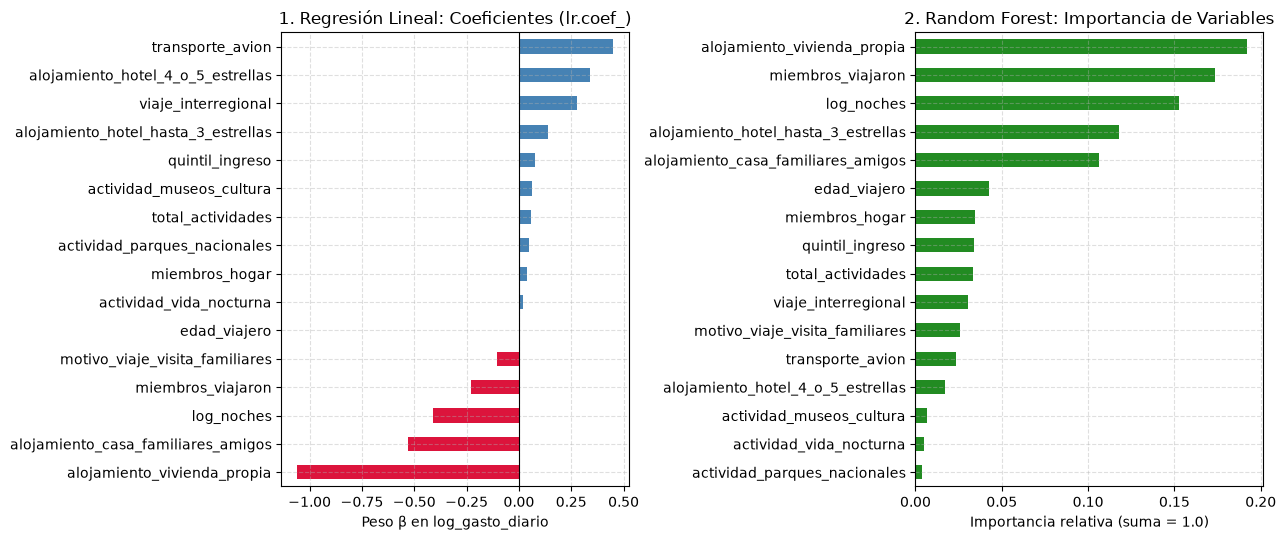

In [739]:
# 6.3. Interpretabilidad: Coeficientes de Regresión Lineal vs. Importancia en Random Forest
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Panel 1: Coeficientes de Regresión Lineal (lr.coef_)
coefs_crudos = pd.Series(lr.coef_, index=features_seleccionadas).sort_values()
colores_crudos = ["crimson" if v < 0 else "steelblue" for v in coefs_crudos]
coefs_crudos.plot(kind="barh", ax=axes[0], color=colores_crudos)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("1. Regresión Lineal: Coeficientes (lr.coef_)")
axes[0].set_xlabel("Peso β en log_gasto_diario")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Panel 2: Importancia en Random Forest
imp_rf = pd.Series(rf.feature_importances_, index=features_seleccionadas).sort_values()
imp_rf.plot(kind="barh", ax=axes[1], color="forestgreen")
axes[1].set_title("2. Random Forest: Importancia de Variables")
axes[1].set_xlabel("Importancia relativa (suma = 1.0)")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

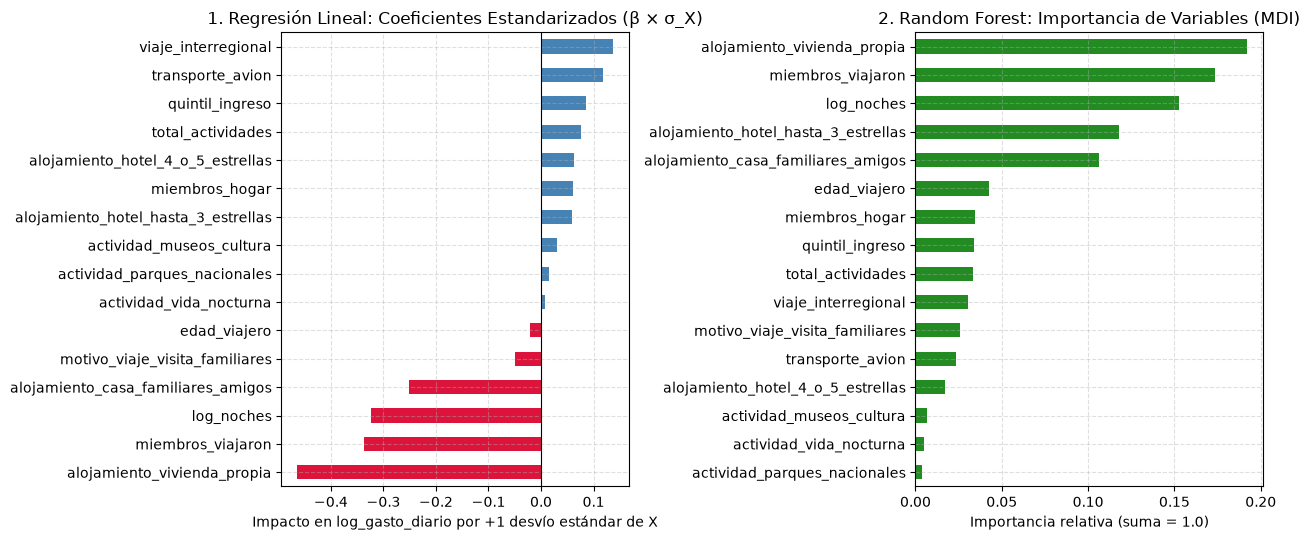

In [740]:
# 6.4. Coeficientes Estandarizados de Regresión Lineal vs. Importancia en Random Forest
# Al ponderar lr.coef_ por el desvío estándar de cada variable (β × σ_X), se mide el impacto sobre la varianza poblacional,
# quedando bajo el mismo criterio de ordenamiento que la reducción de varianza (MDI) de Random Forest.
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# Panel 1: Coeficientes Estandarizados de Regresión Lineal (β × σ_X)
coefs_std = pd.Series(
    lr.coef_ * X_train.std().values, index=features_seleccionadas
).sort_values()
colores_std = ["crimson" if v < 0 else "steelblue" for v in coefs_std]
coefs_std.plot(kind="barh", ax=axes[0], color=colores_std)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("1. Regresión Lineal: Coeficientes Estandarizados (β × σ_X)")
axes[0].set_xlabel("Impacto en log_gasto_diario por +1 desvío estándar de X")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Panel 2: Importancia en Random Forest (MDI)
imp_rf = pd.Series(rf.feature_importances_, index=features_seleccionadas).sort_values()
imp_rf.plot(kind="barh", ax=axes[1], color="forestgreen")
axes[1].set_title("2. Random Forest: Importancia de Variables (MDI)")
axes[1].set_xlabel("Importancia relativa (suma = 1.0)")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 7. Conclusiones

### 7.1. Determinantes del Gasto Turístico Diario
* **Factores que incrementan el gasto:** El uso de **transporte aéreo**, el alojamiento en **hoteles de 4 o 5 estrellas**, el desplazamiento fuera de la propia región (**`viaje_interregional`**) y la cantidad de **actividades turísticas** realizadas (**`total_actividades`**).
* **Factores que reducen el gasto:** El alojamiento en **vivienda propia** o en **casa de familiares/amigos** reduce drásticamente el presupuesto diario al eliminar el costo de hospedaje. Asimismo, se verifican **economías de escala** en el tamaño del grupo (**`miembros_viajaron`**, por división de gastos fijos entre acompañantes) y en la duración del viaje (**`log_noches`**, por amortización del transporte en estadías largas y compresión de estadías extremas).
* **Asimetría de peso entre predictores de ahorro y de lujo:** Tanto en los coeficientes estandarizados de la Regresión Lineal como en la importancia del Random Forest, las variables que reducen el gasto (`alojamiento_vivienda_propia`, `alojamiento_casa_familiares_amigos`, `miembros_viajaron` y `log_noches`) tienen un peso poblacional **3 a 4 veces mayor** que las asociadas a viajes caros (`transporte_avion`, `alojamiento_hotel_4_o_5_estrellas`). Esto indica que, en el turismo interno argentino, **saber quién no paga hospedaje y cómo se reparte el costo fijo entre personas y días es un indicador mucho más determinante del gasto que el consumo de lujo** (el cual representa a una fracción minoritaria de la muestra).

### 7.2. Comparación entre Regresión Lineal y Random Forest (Desempeño e Interpretabilidad)
* **Desempeño y estructura de los datos:** El **Random Forest Regressor** ajustado (`min_samples_leaf=30, max_features=0.5`) y la **Regresión Lineal Múltiple** alcanzaron un desempeño muy cercano tanto en validación (`2023`) como en test (`2024`). Tras el One-Hot Encoding y la transformación `log_noches`, la relación con el gasto en escala logarítmica resulta mayormente aditiva. En **Random Forest** fue clave regularizar el tamaño mínimo de hoja (`min_samples_leaf=30`) para evitar el sobreajuste al ruido de la encuesta.
* **Interpretabilidad (Signo vs. Magnitud):** Al comparar los **coeficientes estandarizados** de la Regresión Lineal ($\beta_j \times \sigma_{X_j}$, que miden cuánto mueve la predicción el término completo $\beta_j X_j$ en la población) frente a la **importancia por reducción de varianza (MDI)** del Random Forest, ambos modelos coinciden en cuáles son las variables más determinantes (`alojamiento_vivienda_propia`, `miembros_viajaron`, `log_noches`, `alojamiento_hotel_hasta_3_estrellas`). Sin embargo, la **Regresión Lineal ofrece una ventaja clara de interpretabilidad**: sus coeficientes indican el **sentido del efecto** (signo positivo si encarece el viaje, negativo si lo abarata), mientras que la importancia de **Random Forest** solo entrega una magnitud positiva (cuánta varianza redujo la variable en los cortes `if/else`), sin informar si la variable sube o baja el gasto.

### 7.3. Limitaciones y Shock Macroeconómico de 2024
* Mientras que en un año estable como **2023** ambos modelos logran un ajuste sólido ($R^2 \approx 0.24$, correlación $r \approx 0.56$), en el conjunto de test (**2024**) se observa una caída abrupta del gasto real promedio de `5.87` a `5.50` en escala logarítmica (~31% menos en pesos constantes) tras la devaluación e inflación de fines de 2023.
* Como los modelos solo reciben atributos del viaje y desconocen la caída del poder adquisitivo salarial, mantienen su capacidad para **ordenar correctamente a los turistas** de menor a mayor gasto en 2024 ($r \approx 0.39$), pero sufren un **sesgo sistemático de sobreestimación (`+0.38`)** que penaliza la métrica $R^2$.

### 7.4. Posibles Mejoras e Implicancias Éticas
* **Mejoras futuras:** Incorporar variables macroeconómicas trimestrales de poder adquisitivo (como el índice salarial RIPTE, el ingreso medio de la EPH o el tipo de cambio real) permitiría que el modelo ajuste su nivel base ante recesiones o shocks cambiarios.
* **Implicancias éticas y sesgos del dataset:**
  1. **Sesgo de cobertura socioeconómica y geográfica:** La encuesta EVyTH releva únicamente grandes aglomerados urbanos y registra hogares que efectivamente pudieron costear un viaje, excluyendo a poblaciones rurales y sectores vulnerables sin acceso al turismo.
  2. **Sesgo de autodeclaración:** Los montos de gasto son declarados de memoria por el encuestado luego del viaje, lo que introduce error de medición y redondeo. Utilizar estos modelos para planificar infraestructura pública o políticas tarifarias sin contemplar estos sesgos podría reforzar desigualdades a favor de los segmentos de mayor poder adquisitivo.
